the below two cell is for collab this practical can perfrom without dataset cause its inbuilt in the library.

In [40]:
from google.colab import files
uploaded = files.upload()

Saving iris.csv to iris.csv


In [41]:
df = pd.read_csv("iris.csv")

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


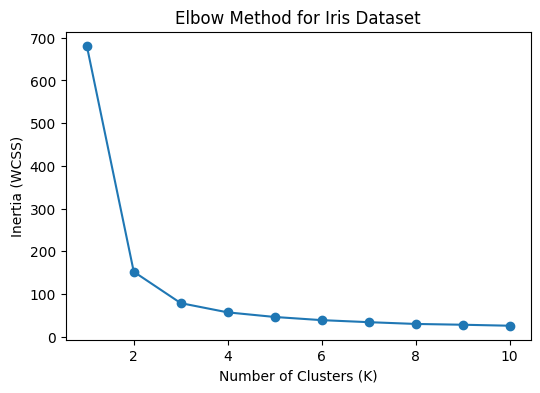

Optimal K = 3


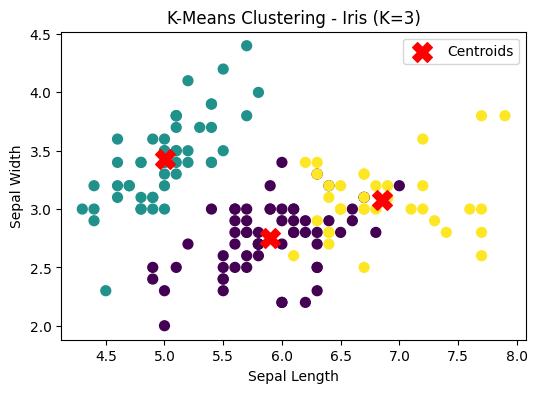

In [35]:
# SINGLE CELL CODE - No CSV needed
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

# 1. Load Iris Dataset (150 flowers, 4 features)
iris = load_iris()
X = iris.data  # Use only features for clustering (unsupervised)
# If teacher gave you Iris.csv, use this instead:
# df = pd.read_csv("/content/Iris.csv")
# X = df.iloc[:, 0:4]

# 2. Elbow Method - To find best K
inertia = [] # WCSS - sum of distances
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method for Iris Dataset')
plt.show()

# 3. From graph, elbow is at K=3 (because iris has 3 species)
# Now final clustering with K=3
best_k = 3
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = final_kmeans.fit_predict(X)

print(f"Optimal K = {best_k}")

# 4. Visualize Clusters (using first 2 features)
plt.figure(figsize=(6,4))
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', s=50)
plt.scatter(final_kmeans.cluster_centers_[:, 0], final_kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.title('K-Means Clustering - Iris (K=3)')
plt.legend()
plt.show()